In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

chunks = []

for chunk in pd.read_csv(
    "/home/user/branes/NER-data/NER-inference_1946-2025.csv",
    chunksize=2000
):
    chunks.append(chunk)

df = pd.concat(chunks, ignore_index=True)
print("Deberta base 5. epoch")
print(df.shape)

df_ner = df.copy()

def build_golden_list(df_instrument: pd.DataFrame) -> list[str]:
    if df_instrument.empty:
        return []

    golden_list = []

    # Official titles
    titles = [
        t.strip()
        for t in df_instrument["title"].dropna()
        if t.strip()
    ]

    # Alternative names
    aliases = []
    for value in df_instrument["alternative_name"].dropna():
        aliases.extend(
            p.strip()
            for p in value.split(";")
            if p.strip()
        )

    golden_list.extend(titles)
    golden_list.extend(aliases)

    return golden_list

Deberta base 5. epoch
(64290, 7)


In [2]:
    
df_90 = df[df["score"] > 0.90]
print(df_90.shape)


(51055, 7)


In [3]:
df_90.head(30)

,doc_id,doc_year,text,score,start,end,label
0,A/HRC/RES/12/16,2009,International Covenant on Civil and Political Rights,0.999594,2596,2649,INSTRUMENT
1,A/HRC/RES/12/16,2009,International Covenant on Civil and Political Rights,0.999687,2789,2842,INSTRUMENT
2,A/HRC/RES/12/16,2009,International Covenant on Civil and Political Rights,0.999548,8815,8868,INSTRUMENT
3,A/HRC/RES/12/16,2009,International Covenant on Civil and Political Rights,0.999362,9921,9974,INSTRUMENT
4,A/HRC/RES/12/17,2009,Charter of the United Nations,0.999917,437,467,INSTRUMENT
5,A/HRC/RES/12/17,2009,"International Covenant on Economic, Social and Cultural Rights",0.999719,560,623,INSTRUMENT
6,A/HRC/RES/12/17,2009,International Covenant on Civil and Political Rights,0.999564,628,681,INSTRUMENT
7,A/HRC/RES/12/17,2009,Convention on the Elimination of All Forms of Discrimination against Women,0.999797,686,761,INSTRUMENT
8,A/HRC/RES/12/17,2009,International Convention on the Elimination of All Forms of Racial Discrimination,0.999764,769,851,INSTRUMENT
9,A/HRC/RES/12/17,2009,Vienna Declaration and Programme of Action,0.999480,867,910,INSTRUMENT


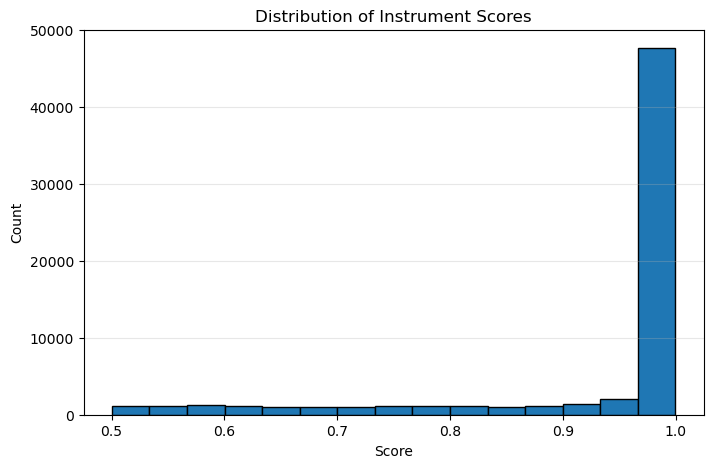

In [4]:
plt.figure(figsize=(8, 5))
plt.hist(df["score"].dropna(), bins=15, edgecolor="black")
plt.xlabel("Score")
plt.ylabel("Count")
plt.title("Distribution of Instrument Scores")
plt.grid(axis="y", alpha=0.3)
plt.show()

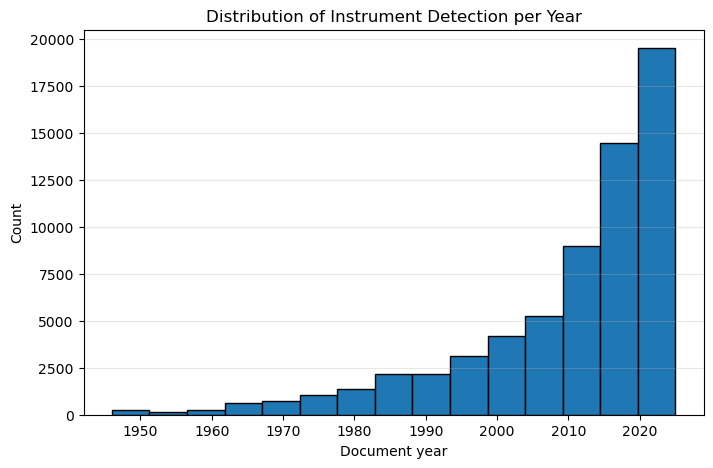

In [5]:
plt.figure(figsize=(8, 5))
plt.hist(df["doc_year"].dropna(), bins=15, edgecolor="black")
plt.xlabel("Document year")
plt.ylabel("Count")
plt.title("Distribution of Instrument Detection per Year")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [6]:
bins   = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
labels = ["0.5-0.6", "0.6-0.7", "0.7-0.8", "0.8-0.9", "0.9-1.0"]

# right=False -> each bin is [low, high), so 0.6 goes in the 0.6-0.7 bin
df["score_bin"] = pd.cut(df["score"], bins=bins, labels=labels, right=False)

top30 = (
    df.groupby("score_bin", observed=True)["text"]
      .value_counts()                 # sorted descending within each bin
      .groupby(level=0).head(30)      # keep the first 30 per bin
      .rename("count")
      .reset_index()
)

for b, g in top30.groupby("score_bin", observed=True):
    print(f"\n=== score {b} ===")
    print(g[["text", "count"]].to_string(index=False))

df = df.drop(columns=["score_bin"])


=== score 0.5-0.6 ===
         text  count
          for    320
  Development    216
           of    167
          the    148
          and     78
       Sendai     60
           on     58
            ,     50
        Paris     40
   Convention     34
    Agreement     28
       global     25
   convention     23
            .     23
            s     23
            A     21
  Declaration     19
           to     19
       of the     17
       on the     17
          FCC     16
         Risk     16
           or     16
       stocks     15
 Measures for     14
     Offender     14
           in     14
          No.     14
     Property     13
     protocol     13

=== score 0.6-0.7 ===
                                         text  count
                                          for    208
                                  Development    186
                  for Sustainable Development     89
                                          the     66
                                      

In [7]:
mask = (
    df["text"].str.contains("geneva", case=False, na=False)
    & (df["doc_year"] > 2015)
)

df.loc[mask, "text"].value_counts()


 Geneva Convention relative to the Protection of Civilian Persons in Time of War                                                                                208
 Fourth Geneva Convention                                                                                                                                       141
 geneva convention relative to the protection of civilian persons in time of war                                                                                 62
 Geneva communiqué                                                                                                                                               38
 fourth geneva convention                                                                                                                                        34
Fourth Geneva Convention                                                                                                                                         11
 Geneva         

In [8]:
df[df["text"].str.lower().str.contains("declaration of human rights")]

,doc_id,doc_year,text,score,start,end,label


In [9]:
cols = ["title", "year", "alternative_name"]

df_wiki = pd.read_csv("/home/user/branes/NER-data/wiki-treaties_formatted.csv")
df_wiki = df_wiki.rename(columns={"name": "title", "cleaned_note": "alternative_name"})[cols]

df_ohchr = pd.read_csv("/home/user/branes/NER-data/ohchr_instruments_detailed-instit.csv")
df_ohchr["year"] = pd.to_datetime(df_ohchr["adoption_date"], format="%d %B %Y").dt.year
df_ohchr = df_ohchr[cols]

df_uno = pd.read_csv("/home/user/branes/NER-data/UNO-Treaties.csv")
df_uno["year"] = pd.to_datetime(df_uno["date"], format="%d %B %Y").dt.year
df_uno["alternative_name"] = ""
df_uno = df_uno[cols]

df_unesco = pd.read_csv("/home/user/branes/NER-data/UNESCO_legal_instruments_detail.csv")
df_unesco["year"] = pd.to_datetime(df_unesco["date"], format="%d %B %Y").dt.year
df_unesco["alternative_name"] = ""
df_unesco = df_unesco[cols]

df_conv_prot_rec = pd.read_csv("/home/user/branes/NER-data/conventions-protocols-recommendations.csv")
df_conv_prot_rec["alternative_name"] = ""
df_conv_prot_rec = df_conv_prot_rec[cols]

ad_hoc = pd.read_csv("/home/user/branes/NER-data/ad_hoc_instruments.csv")
ad_hoc = ad_hoc[cols]

df_instrument = pd.concat(
    [df_wiki, df_ohchr, df_uno, df_unesco, df_conv_prot_rec, ad_hoc],
    ignore_index=True
)
all_instruments = df_instrument.copy()

golden_list = build_golden_list(df_instrument)

df_instrument.head()

,title,year,alternative_name
0,Treaty of Paris,1900,NaN
1,Treaty of Washington,1900,NaN
2,"Convention for the Preservation of Wild Animals, Birds and Fish in Africa",1900,NaN
3,Hay–Pauncefote Treaty,1901,NaN
4,Boxer Protocol,1901,Peace Agreement between the Great Powers and China


In [13]:
t = df_instrument["title"].str.strip().str.lower()

# 2. Repeated names anywhere (title + each alternative name)
rows = []
for i, r in df_instrument.iterrows():
    alts = str(r["alternative_name"]).split(";") if pd.notna(r["alternative_name"]) else []
    for n in [r["title"], *alts]:
        if n.strip():
            rows.append((i, n.strip().lower()))

names = pd.DataFrame(rows, columns=["row", "name"])
counts = names.groupby("name")["row"].nunique()   # counts distinct rows, so title/alt overlap in one row is ignored


In [11]:
import re, unicodedata
#%pip install rapidfuzz
from rapidfuzz import process
from rapidfuzz.distance import Levenshtein

def normalize(s: str) -> str:
    s = unicodedata.normalize("NFKC", s).casefold()
    s = re.sub(r"[‐‑–—−]", "-", s)
    return " ".join(s.split())

# normalizado -> nombre original (también deduplica entre fuentes)
golden_norm = {normalize(g): g for g in golden_list}

df_ner["text_norm"] = df_ner["text"].map(normalize)
df_ner["golden_match"] = df_ner["text_norm"].map(golden_norm)   # NaN si no hay match
df_ner["exact_match"] = df_ner["golden_match"].notna()

# Nivel 2: fuzzy solo para los no resueltos
keys = list(golden_norm)
def best_candidate(t):
    m = process.extractOne(
        t, keys,
        scorer=Levenshtein.normalized_similarity,  # 0..1
        score_cutoff=0.9,
    )
    return m  # (candidato, score, idx) o None
    
print(f"length of all NER entries: {len(df_ner)}")

rest = df_ner.loc[~df_ner["exact_match"], "text_norm"]
df_ner.loc[rest.index, "fuzzy_candidate"] = rest.map(best_candidate)
print(rest.head())

length of all NER entries: 64290
23                                                                       agreement on
24                                                                -related aspects of
25                                                                             rights
32    international convention on the protection of the rights of all migrant workers
33                                                          members of their families
Name: text_norm, dtype: object


In [12]:

# --------------------------------------------------
# 1. to_rank_alias_all.csv
# Exact matches against titles/aliases of instruments
# that have a non-empty alternative_name
# --------------------------------------------------

df_alias_instruments = df_instrument[
    df_instrument["alternative_name"].notna()
    & df_instrument["alternative_name"].astype(str).str.strip().ne("")
]

alias_names = set()

for _, row in df_alias_instruments.iterrows():
    # Include the official title
    if pd.notna(row["title"]) and str(row["title"]).strip():
        alias_names.add(normalize(str(row["title"]).strip()))

    # Include every alias, separated by semicolons
    for alias in str(row["alternative_name"]).split(";"):
        alias = alias.strip()
        if alias:
            alias_names.add(normalize(alias))

to_rank_alias = df_ner[
    df_ner["exact_match"].fillna(False)
    & df_ner["text_norm"].isin(alias_names)
].copy()

# Save the full dataset
to_rank_alias.to_csv(
    "/home/user/branes/NER-data/to_rank_alias_all.csv",
    index=False
)

# Save a random sample of up to 1,000 rows
to_rank_alias_sample = to_rank_alias.sample(
    n=min(1000, len(to_rank_alias)),
    random_state=42
)

to_rank_alias_sample.to_csv(
    "/home/user/branes/NER-data/to_rank_alias.csv",
    index=False
)


# --------------------------------------------------
# 2. to_rank_no_match_all.csv
# No exact match and score >= 0.90
# --------------------------------------------------

to_rank_no_match = df_ner[
    ~df_ner["exact_match"].fillna(False)
    & (pd.to_numeric(df_ner["score"], errors="coerce") >= 0.90)
].copy()

# Save the full dataset
to_rank_no_match.to_csv(
    "/home/user/branes/NER-data/to_rank_no_match_all.csv",
    index=False
)

# Save a random sample of up to 1,000 rows
to_rank_no_match_sample = to_rank_no_match.sample(
    n=min(1000, len(to_rank_no_match)),
    random_state=42
)

to_rank_no_match_sample.to_csv(
    "/home/user/branes/NER-data/to_rank_no_match.csv",
    index=False
)


# --------------------------------------------------
# Summary
# --------------------------------------------------

print(f"Saved to_rank_alias_all.csv: {len(to_rank_alias)} rows")
print(f"Saved to_rank_alias.csv: {len(to_rank_alias_sample)} rows")

print(f"Saved to_rank_no_match_all.csv: {len(to_rank_no_match)} rows")
print(f"Saved to_rank_no_match.csv: {len(to_rank_no_match_sample)} rows")


Saved to_rank_alias_all.csv: 9052 rows
Saved to_rank_alias.csv: 1000 rows
Saved to_rank_no_match_all.csv: 5532 rows
Saved to_rank_no_match.csv: 1000 rows
